In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time
import math

# Distribuição Gamma

## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [2]:
def densidade_gama(x, a, b):
    return b**a / math.gamma(a) * x**(a-1) * np.exp(-b*x)   # forma taxa

In [3]:
lbd = 10
n = 50
M = 1_000_000

In [4]:
x = np.linspace(3,8)
fx = densidade_gama(x, n, lbd)

In [5]:
U = np.random.uniform(size=(M,n))
exp = (-1)*np.log(U)/lbd
gama = np.sum(exp, axis=1)


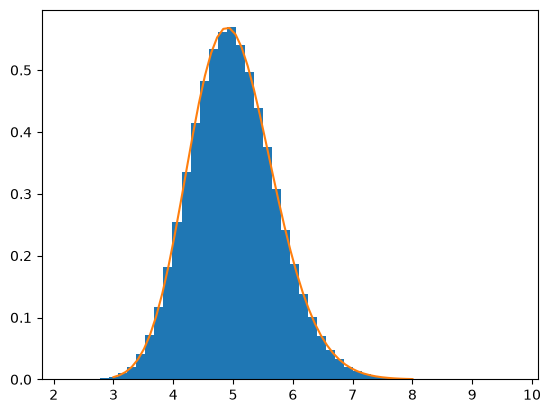

In [6]:
plt.hist(gama, density=True, bins=50)
plt.plot(x,fx)

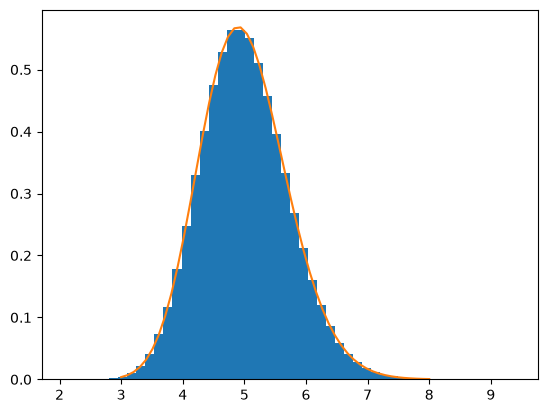

In [7]:
plt.hist(np.random.gamma(n, 1/lbd, size = M), density=True, bins=50)
plt.plot(x,fx)
plt.show()

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [8]:
def densidade_gama(x, a, b):
    return b**a / math.gamma(a) * x**(a-1) * np.exp(-b*x)   # forma taxa


def densidade_exp(x, lamb=1):
    return lamb*np.exp(-x*lamb)

In [9]:
mi = 3 # parâmetro da exponencial
a = 2.5
lamb = 10 # mi sempre menor q lamb

In [10]:
x_melhor = (a-1)/(lamb-mi)
print(x_melhor)

0.21428571428571427


In [11]:
c = densidade_gama(x_melhor, a, lamb) / densidade_exp(x_melhor, mi)
print(c)

1.7550546778864502


### Usando um for e um while

In [12]:
M = 10_000
amostras_gama = []
for _ in range(M):
    U = np.random.uniform()
    exp = (-1)*np.log(np.random.uniform())/mi
    while U * c * densidade_exp(exp, mi) > densidade_gama(exp, a, lamb):
        U = np.random.uniform()
        exp = (-1)*np.log(np.random.uniform())/mi
    amostras_gama.append(exp)

In [13]:
x = np.linspace(0, 3)
fx = densidade_gama(x, a, lamb)

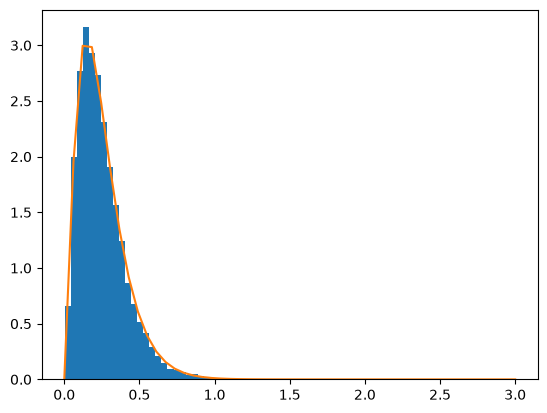

In [14]:
plt.hist(amostras_gama, density= True, bins=30)
plt.plot(x,fx)

### Usando só um loop

In [15]:
sucessos = 0
teste = []
while sucessos < M:
    U = np.random.uniform()
    exp = (-1)*np.log(np.random.uniform())/mi
    if U * c * densidade_exp(exp,mi) < densidade_gama(exp,a,lamb):
        teste.append(exp)
        sucessos += 1
        

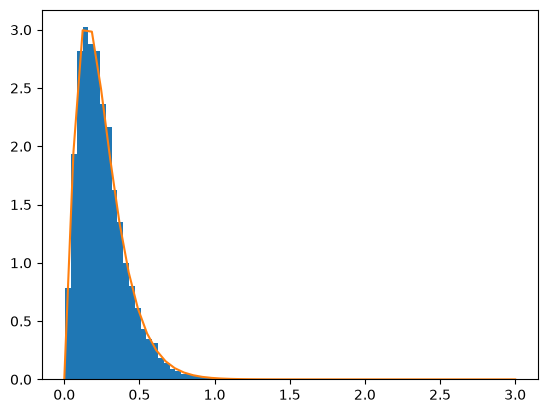

In [16]:
plt.hist(teste, density = True, bins=30)
plt.plot(x,fx)

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha<1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

In [17]:
mi = 3 # parametro da exponencial
a = .5
lamb = 10 # mi sempre menor q lamb

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [18]:
sucessos = 0
amostra_gama_maior_que_1 = []
while sucessos < M:
    U = np.random.uniform()
    exp = (-1)*np.log(np.random.uniform())/mi
    if U * c * densidade_exp(exp,mi) < densidade_gama(exp,a+1,lamb):
        amostra_gama_maior_que_1.append(exp)
        sucessos += 1

In [19]:
amostra_gama_menor_1 = amostra_gama_maior_que_1*(np.random.uniform(size=M)**(1/a))

In [20]:
z = np.linspace(0.01,1)
fz = densidade_gama(z, a, lamb)

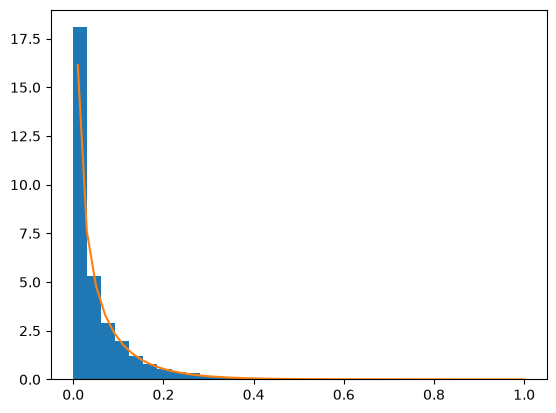

In [21]:
plt.hist(amostra_gama_menor_1, density=True, bins=30)
plt.plot(z,fz)

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [22]:
def densidade_beta(x,a,b):
    return (x**(a-1))*((1-x)**(b-1))*(math.gamma(a+b)/(math.gamma(a)*math.gamma(b)))

In [23]:
M = 10_000
a = 6
b = 7
sucessos = 0
amostra_beta = []

In [24]:
sub = np.linspace(0,1, num=100)
c = np.max(densidade_beta(sub, 6, 7)) + 0.01

In [26]:
w = np.linspace(0,1)
fw = densidade_beta(w, 6, 7)

In [27]:
while sucessos < M:
    U = np.random.uniform()
    y = np.random.uniform()
    if U * c < densidade_beta(y, 6, 7):
        amostra_beta.append(y)
        sucessos += 1

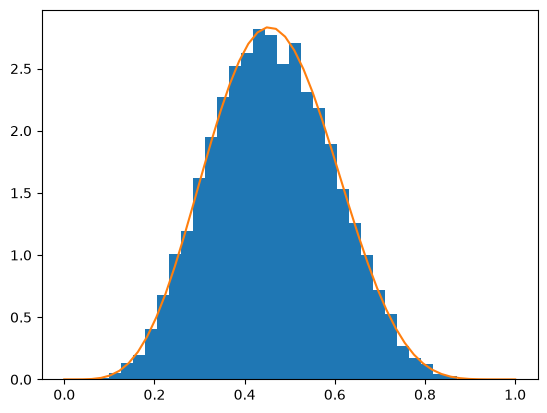

In [28]:
plt.hist(amostra_beta, density=True, bins=30)
plt.plot(w,fw)

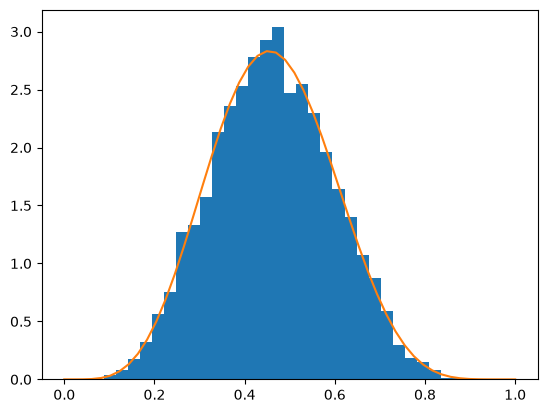

In [30]:
plt.hist(np.random.beta( 6, 7, size=10_000), density=True, bins=30)
plt.plot(w,fw)

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [ ]:
alfa = alfa
beta = beta